# 🧩 Resolución de Laberintos — 5 Estrategias de Diseño de Algoritmos

**Curso:** Análisis y Diseño de Algoritmos — 2026-2
**Integrantes:** Alejandro Bermudez, Juan David Mosquera, Santiago Restrepo
**Caso de uso:** 3.3 Juego o Puzzle (Laberinto)

En la Entrega 1 ([`laberinto.py`](laberinto.py)) resolvimos el laberinto con una búsqueda recursiva que se detiene en el **primer** camino que encuentra.
Ahora el problema es más exigente: **encontrar el camino MÁS CORTO** desde `inicio` hasta `fin`. Así podemos comparar no solo la velocidad,
sino también la **calidad** de la respuesta de cada estrategia:

| # | Estrategia | Idea en una línea |
|---|---|---|
| 1 | **Fuerza bruta** | Probar *todos* los caminos posibles y quedarse con el más corto. |
| 2 | **Backtracking con poda** | Igual que la fuerza bruta, pero abandonando ramas que ya no pueden mejorar la mejor solución. |
| 3 | **Voraz (Greedy)** | En cada paso avanzar hacia la casilla que *parece* más cercana a la meta. |
| 4 | **Divide y vencerás** | Partir el viaje `A→B` en dos mitades `A→M` y `M→B` y resolver cada una recursivamente. |
| 5 | **Programación dinámica** | Llenar una tabla `dist[x][y]` con la distancia mínima a cada casilla, reutilizando subproblemas. |

Al final medimos **tiempo**, **memoria** y **casillas exploradas** en laberintos de hasta **2001 × 2001** (≈ 2 000 000 de casillas libres)
y exportamos los resultados a `resultados.js`, que usa la presentación interactiva [`index.html`](index.html).

## 1. Representación y utilidades comunes

Usamos la misma representación de la Entrega 1: una matriz de emojis donde `⬜` es libre y `⬛` es pared.
Los movimientos se prueban en el mismo orden de antes: **abajo, derecha, arriba, izquierda**.

In [1]:
import sys, time, random, heapq, tracemalloc, json

sys.setrecursionlimit(1_000_000)  # la fuerza bruta y el backtracking son recursivos

LIBRE, PARED, CAMINO = "⬜", "⬛", "🟩"
MOVIMIENTOS = [(1, 0), (0, 1), (-1, 0), (0, -1)]  # abajo, derecha, arriba, izquierda


def vecinos(tablero, celda):
    """Lista de casillas libres al lado de `celda` (sin salirse del tablero)."""
    x, y = celda
    resultado = []
    for dx, dy in MOVIMIENTOS:
        nx = x + dx
        ny = y + dy
        if 0 <= nx < len(tablero) and 0 <= ny < len(tablero[0]):
            if tablero[nx][ny] == LIBRE:
                resultado.append((nx, ny))
    return resultado


def manhattan(a, b):
    """Distancia "por cuadras" entre dos casillas: cota inferior de los pasos que faltan."""
    return abs(a[0] - b[0]) + abs(a[1] - b[1])


def imprimir_laberinto(tablero, camino=()):
    """Dibuja el tablero marcando el camino con 🟩 (sin modificar el original)."""
    for x in range(len(tablero)):
        fila = ""
        for y in range(len(tablero[0])):
            if (x, y) in camino:
                fila += CAMINO
            else:
                fila += tablero[x][y]
        print(fila)
    print()


class LimiteExcedido(Exception):
    """Se lanza cuando un algoritmo exponencial supera su presupuesto de operaciones."""

## 2. Generador de laberintos (pequeños y gigantescos)

Para probar con laberintos enormes necesitamos generarlos. Usamos el algoritmo clásico *recursive backtracker* (DFS iterativo):

* Las casillas en coordenadas **pares** son "cuartos"; entre dos cuartos hay una pared que se puede derribar.
* El resultado es un **laberinto perfecto**: existe exactamente **un** camino entre dos casillas cualesquiera.
* Con `ciclos > 0` derribamos paredes extra al azar → aparecen **muchos caminos alternativos** (el peor caso para la fuerza bruta).

Por convención (igual que en la Entrega 1) el inicio es `(0, 0)` y el fin la esquina opuesta `(N-1, M-1)`.

In [2]:
def generar_laberinto(n, m, ciclos=0.0, semilla=0):
    """Laberinto n x m (n y m impares). `ciclos` = probabilidad de derribar una pared extra."""
    assert n % 2 == 1 and m % 2 == 1, "Las dimensiones deben ser impares"
    rnd = random.Random(semilla)
    tablero = [[PARED] * m for _ in range(n)]
    tablero[0][0] = LIBRE
    pila = [(0, 0)]
    while pila:  # DFS iterativo para no desbordar la pila en tableros gigantes
        x, y = pila[-1]
        opciones = [(x + dx, y + dy, x + dx // 2, y + dy // 2)
                    for dx, dy in ((2, 0), (0, 2), (-2, 0), (0, -2))
                    if 0 <= x + dx < n and 0 <= y + dy < m and tablero[x + dx][y + dy] == PARED]
        if not opciones:
            pila.pop()
            continue
        nx, ny, px, py = rnd.choice(opciones)
        tablero[px][py] = tablero[nx][ny] = LIBRE
        pila.append((nx, ny))
    for x in range(n):  # paredes "entre cuartos" (una coordenada par y otra impar)
        for y in range(m):
            if (x + y) % 2 == 1 and tablero[x][y] == PARED and rnd.random() < ciclos:
                tablero[x][y] = LIBRE
    return tablero


ejemplo = generar_laberinto(11, 21, semilla=7)
imprimir_laberinto(ejemplo)

⬜⬜⬜⬛⬜⬜⬜⬛⬜⬜⬜⬜⬜⬛⬜⬜⬜⬜⬜⬜⬜
⬛⬛⬜⬛⬜⬛⬜⬛⬛⬛⬜⬛⬜⬛⬜⬛⬛⬛⬜⬛⬜
⬜⬛⬜⬜⬜⬛⬜⬛⬜⬜⬜⬛⬜⬛⬜⬜⬜⬛⬜⬛⬜
⬜⬛⬛⬛⬛⬛⬜⬛⬜⬛⬛⬛⬜⬛⬛⬛⬛⬛⬜⬛⬛
⬜⬜⬜⬜⬜⬛⬜⬜⬜⬛⬜⬛⬜⬜⬜⬜⬜⬛⬜⬜⬜
⬜⬛⬜⬛⬛⬛⬛⬛⬛⬛⬜⬛⬛⬛⬛⬛⬜⬛⬜⬛⬜
⬜⬛⬜⬛⬜⬜⬜⬜⬜⬜⬜⬛⬜⬜⬜⬛⬜⬛⬜⬛⬜
⬜⬛⬜⬛⬜⬛⬜⬛⬛⬛⬛⬛⬜⬛⬜⬛⬜⬛⬜⬛⬜
⬜⬛⬜⬛⬜⬛⬜⬜⬜⬛⬜⬜⬜⬛⬜⬛⬜⬛⬜⬛⬜
⬜⬛⬜⬛⬜⬛⬛⬛⬜⬛⬜⬛⬛⬛⬜⬛⬜⬛⬛⬛⬜
⬜⬛⬜⬜⬜⬜⬜⬛⬜⬜⬜⬜⬜⬛⬜⬜⬜⬜⬜⬜⬜



## 3. Estrategia 1 — Fuerza bruta 🔨

**Nombre conocido:** búsqueda exhaustiva (*exhaustive search*): enumera todos los caminos simples con una búsqueda en profundidad (DFS).

**Idea:** generar **todos** los caminos simples (sin repetir casillas) desde el inicio, y de los que llegan al fin quedarse con el más corto.
No usa ninguna información para descartar trabajo: aunque ya tenga una solución, sigue probando todas las demás.

**Complejidad:**
* **Tiempo:** $O(4^{N \cdot M})$ en el peor caso — cada casilla puede ramificar en hasta 4 direcciones (3 sin contar la de llegada, $O(3^{V})$).
* **Espacio:** $O(N \cdot M)$ — la profundidad de la recursión y el conjunto del camino actual.

Como es exponencial, le damos un **presupuesto** de llamadas; si lo supera, decimos que "no terminó".

In [3]:
def fuerza_bruta(tablero, inicio, fin, limite=2_000_000):
    """Prueba TODOS los caminos y devuelve (camino_mas_corto, casillas_exploradas)."""
    datos = {"mejor": None, "explorados": 0}   # lo que se recuerda entre llamadas
    visitado = []
    for fila in tablero:
        visitado.append([False] * len(fila))
    explorar_fb(tablero, inicio, fin, [], visitado, datos, limite)
    return datos["mejor"], datos["explorados"]


def explorar_fb(tablero, celda, fin, camino, visitado, datos, limite):
    datos["explorados"] += 1
    if datos["explorados"] > limite:
        raise LimiteExcedido
    x, y = celda
    camino.append(celda)                      # avanzar a la casilla
    visitado[x][y] = True
    if celda == fin:
        if datos["mejor"] is None or len(camino) < len(datos["mejor"]):
            datos["mejor"] = list(camino)     # nueva mejor solución, pero SIGUE buscando
    else:
        for v in vecinos(tablero, celda):
            if not visitado[v[0]][v[1]]:      # única regla: no repetir casillas
                explorar_fb(tablero, v, fin, camino, visitado, datos, limite)
    camino.pop()                              # retroceder para probar otra rama
    visitado[x][y] = False

## 4. Estrategia 2 — Backtracking con poda ✂️

**Nombre conocido:** ramificación y poda (*branch and bound*) sobre una búsqueda en profundidad, con poda por dominancia.

Es la misma búsqueda recursiva, pero **antes de bajar por una rama preguntamos si vale la pena**. Usamos dos podas:

1. **Poda por cota (branch & bound):** si `pasos_dados + manhattan(v, fin) ≥ mejor_longitud`, ni siquiera yendo en línea recta mejoraríamos → se descarta.
2. **Poda por dominancia:** guardamos `llegada[x][y]`, los pasos con los que ya llegamos a `v`. Si volvemos a `v` con **igual o más** pasos, todo lo que se
   pueda hacer desde ahí ya se hizo con un camino mejor → se descarta. (Esta poda también evita los ciclos.)

Además ordenamos los vecinos **primero los que acercan a la meta**, para encontrar pronto una buena solución y que la poda 1 corte más.

**Complejidad:**
* **Tiempo:** cada casilla solo se re-visita si llegamos con *estrictamente menos* pasos, así que se visita a lo sumo $V$ veces → $O(V^2) = O((N \cdot M)^2)$
  en el peor caso. En la práctica es muchísimo menor que la fuerza bruta (pasa de exponencial a polinomial).
* **Espacio:** $O(N \cdot M)$ — la recursión y la tabla `llegada`.

In [4]:
def backtracking_poda(tablero, inicio, fin, limite=5_000_000):
    """Búsqueda recursiva con poda por cota y por dominancia. Devuelve (camino, explorados)."""
    datos = {"mejor": None, "explorados": 0}
    llegada = []                              # llegada[x][y] = menos pasos con que llegamos ahí (-1 = nunca)
    for fila in tablero:
        llegada.append([-1] * len(fila))
    llegada[inicio[0]][inicio[1]] = 0
    explorar_bt(tablero, inicio, fin, [], llegada, datos, limite)
    return datos["mejor"], datos["explorados"]


def explorar_bt(tablero, celda, fin, camino, llegada, datos, limite):
    datos["explorados"] += 1
    if datos["explorados"] > limite:
        raise LimiteExcedido
    camino.append(celda)
    if celda == fin:
        datos["mejor"] = list(camino)         # gracias a la poda 1, siempre es más corta que la anterior
    else:
        pasos = len(camino)                   # pasos que tendríamos al llegar a un vecino
        for v in ordenar_por_cercania(vecinos(tablero, celda), fin):
            vx, vy = v
            mejor = datos["mejor"]
            if mejor is not None and pasos + manhattan(v, fin) >= len(mejor) - 1:
                continue                      # poda 1 (cota): ni en línea recta mejoraría
            if llegada[vx][vy] != -1 and llegada[vx][vy] <= pasos:
                continue                      # poda 2 (dominancia): ya llegamos ahí con menos pasos
            llegada[vx][vy] = pasos
            explorar_bt(tablero, v, fin, camino, llegada, datos, limite)
    camino.pop()                              # retroceder


def ordenar_por_cercania(casillas, fin):
    """Ordena las casillas de la más cercana a la más lejana de `fin` (son 4 como mucho)."""
    ordenadas = []
    for c in casillas:
        i = 0
        while i < len(ordenadas) and manhattan(ordenadas[i], fin) <= manhattan(c, fin):
            i += 1
        ordenadas.insert(i, c)
    return ordenadas

## 5. Estrategia 3 — Voraz (Greedy Best-First) 🏃

**Nombre conocido:** búsqueda voraz «primero el mejor» (*Greedy Best-First Search*), con la distancia Manhattan como heurística. Ojo: **no es Dijkstra**. Dijkstra también es voraz, pero elige por la distancia *ya recorrida* y por eso sí garantiza el óptimo (en este laberinto equivale a la estrategia 5). A* combina las dos ideas.

**Idea:** en cada momento expandir la casilla de la frontera que **parece** más cercana a la meta (menor distancia Manhattan),
sin mirar cuánto costó llegar a ella. Una cola de prioridad (*heap*) nos da siempre esa casilla.

* ✅ Muy rápido: suele ir "directo" hacia la meta y explora pocas casillas.
* ❌ **No garantiza el camino más corto**: la decisión local "acercarse a la meta" puede meterlo en un pasillo largo.

**Complejidad:**
* **Tiempo:** $O(V \log V)$ — cada casilla entra y sale del *heap* una vez.
* **Espacio:** $O(V)$ — el *heap* y el diccionario `padre`.

In [5]:
def voraz(tablero, inicio, fin):
    """Greedy best-first: siempre sigue por la casilla que parece más cercana a la meta."""
    frontera = []                             # montículo (heap) de pares (h, casilla)
    heapq.heappush(frontera, (manhattan(inicio, fin), inicio))
    padre = {inicio: None}                    # padre[c] = casilla desde la que llegamos a c
    explorados = 0
    while len(frontera) > 0:
        h, celda = heapq.heappop(frontera)    # decisión voraz: la de menor h
        explorados += 1
        if celda == fin:
            return reconstruir(padre, fin), explorados
        for v in vecinos(tablero, celda):
            if v not in padre:
                padre[v] = celda
                heapq.heappush(frontera, (manhattan(v, fin), v))
    return None, explorados


def reconstruir(padre, fin):
    """Sigue los punteros `padre` desde el fin hasta el inicio y voltea la lista."""
    camino = []
    celda = fin
    while celda is not None:
        camino.append(celda)
        celda = padre[celda]
    camino.reverse()
    return camino

## 6. Estrategia 4 — Divide y vencerás ✂️🧩

**Nombre conocido:** recursión por punto medio, la idea de **Hirschberg** (1975) aplicada a caminos, como en el *Divide-and-Conquer Frontier Search* de Korf (1999). Es el mismo esquema del teorema de Savitch.

**Idea:** el camino más corto de `A` a `B` (de longitud `d`) pasa por una casilla `M` que está **justo a la mitad**:
`dist(A, M) = ⌊d/2⌋` y `dist(M, B) = d − ⌊d/2⌋`.

1. **Dividir:** encontrar ese punto medio `M` (con dos inundaciones *flood fill*: una desde `A` y otra desde `B`, limitadas a radio `d`).
2. **Vencer:** resolver recursivamente `A → M` y `M → B` (cada uno de longitud `d/2`).
3. **Combinar:** concatenar los dos caminos.
4. **Caso base:** si `A` y `B` son la misma casilla o son vecinas, el camino es directo.

**Complejidad** (recurrencia con el Teorema Maestro):

$$T(d) = 2\,T(d/2) + O(B(d))$$

donde $B(d)$ = casillas a distancia $\le d$. En un laberinto de pasillos $B(d) = \Theta(d)$ → **caso 2 del Teorema Maestro**: $T(d) = \Theta(d \log d)$.
En el peor caso (salas abiertas) $B(d)$ llega a $V$ y el trabajo sube a $O(V \cdot d)$.

* **Espacio:** $O(V)$ para las inundaciones + $O(\log d)$ de profundidad de recursión.

> 💡 **Observación clave:** las inundaciones de `A→M` y `M→B` **vuelven a recorrer** casillas que ya habíamos recorrido arriba.
> Los subproblemas **se solapan** — justamente la señal de que conviene **programación dinámica**.

In [6]:
def inundar(tablero, origen, radio):
    """Distancia desde `origen` a cada casilla alcanzable sin pasar de `radio` (None = sin límite)."""
    dist = {origen: 0}
    cola = [origen]
    i = 0
    while i < len(cola):                      # recorre la cola en orden de llegada
        celda = cola[i]
        i += 1
        if radio is not None and dist[celda] == radio:
            continue
        for v in vecinos(tablero, celda):
            if v not in dist:
                dist[v] = dist[celda] + 1
                cola.append(v)
    return dist


def divide_y_venceras(tablero, inicio, fin):
    """Parte A→B en A→M y M→B (M = punto medio de un camino más corto). Devuelve (camino, explorados)."""
    if tablero[inicio[0]][inicio[1]] != LIBRE:
        return None, 0
    datos = {"explorados": 0}
    camino = resolver_dv(tablero, inicio, fin, None, datos)
    return camino, datos["explorados"]


def resolver_dv(tablero, a, b, radio, datos):
    if a == b:                                # caso base: misma casilla
        return [a]
    if manhattan(a, b) == 1:                  # caso base: casillas vecinas
        return [a, b]
    desde_a = inundar(tablero, a, radio)      # DIVIDIR: distancias desde A ...
    if b not in desde_a:
        return None
    d = desde_a[b]
    desde_b = inundar(tablero, b, d)          # ... y desde B
    datos["explorados"] += len(desde_a) + len(desde_b)
    mitad = d // 2
    m = None
    for celda in desde_a:                     # M: a `mitad` pasos de A y a `d - mitad` de B
        if desde_a[celda] == mitad and celda in desde_b and desde_b[celda] == d - mitad:
            m = celda
            break
    desde_a = None                            # ya no se necesitan: libera memoria antes de recursar
    desde_b = None
    izquierda = resolver_dv(tablero, a, m, mitad, datos)       # VENCER: A → M
    derecha = resolver_dv(tablero, m, b, d - mitad, datos)     #         M → B
    izquierda.pop()                           # COMBINAR: quita M para no repetirla
    return izquierda + derecha

## 7. Estrategia 5 — Programación dinámica (tabulación) 📋

**Nombre conocido:** búsqueda en anchura (**BFS**) por capas, que en laberintos se conoce como **algoritmo de Lee** (1961). Con pasos de costo 1 es exactamente lo que haría **Dijkstra**.

**Subproblema:** `dist[x][y]` = mínimo número de pasos para llegar del inicio a la casilla `(x, y)`.

**Recurrencia (subestructura óptima):**

$$dist[v] = \begin{cases} 0 & \text{si } v = \text{inicio} \\ 1 + \min\limits_{u \text{ vecino de } v} dist[u] & \text{en otro caso} \end{cases}$$

**¿En qué orden se llena la tabla?** Por **capas** $k = 0, 1, 2, \dots$: las casillas con `dist = k+1` solo dependen de las de la capa `k`,
que ya están calculadas. Así cada casilla se calcula **una sola vez** y nunca se recalcula (a diferencia de divide y vencerás).

**Reconstrucción:** desde el fin, retroceder siempre a un vecino cuya entrada en la tabla sea `dist − 1`.

> ¿Por qué tabulación y no memoización (*top-down*)? Porque el laberinto tiene **ciclos**: `dist(A)` puede depender de `dist(B)` y
> `dist(B)` de `dist(A)`, y una recursión con memo entraría en un bucle. Llenando por capas el orden de dependencias queda bien definido.

**Complejidad:**
* **Tiempo:** $O(N \cdot M)$ — cada casilla se llena una vez y mira 4 vecinos.
* **Espacio:** $O(N \cdot M)$ — la tabla `dist`.

In [7]:
def programacion_dinamica(tablero, inicio, fin):
    """Tabla dist[x][y] llenada por capas y camino reconstruido desde la tabla. Devuelve (camino, explorados)."""
    if tablero[inicio[0]][inicio[1]] != LIBRE:
        return None, 0
    dist = []                                 # dist[x][y] = pasos mínimos desde el inicio (-1 = sin calcular)
    for fila in tablero:
        dist.append([-1] * len(fila))
    dist[inicio[0]][inicio[1]] = 0
    capa = [inicio]
    explorados = 0
    while len(capa) > 0 and dist[fin[0]][fin[1]] == -1:     # llenar la tabla capa por capa
        siguiente = []
        for celda in capa:
            explorados += 1
            x, y = celda
            for vx, vy in vecinos(tablero, celda):
                if dist[vx][vy] == -1:
                    dist[vx][vy] = dist[x][y] + 1
                    siguiente.append((vx, vy))
        capa = siguiente
    if dist[fin[0]][fin[1]] == -1:
        return None, explorados
    camino = [fin]                            # reconstrucción: desde la meta, ir al vecino con un paso menos
    celda = fin
    while celda != inicio:
        x, y = celda
        for v in vecinos(tablero, celda):
            if dist[v[0]][v[1]] == dist[x][y] - 1:
                celda = v
                break
        camino.append(celda)
    camino.reverse()
    return camino, explorados

## 8. Verificación de corrección ✅

Antes de medir, comprobamos que los algoritmos funcionan:

* Todo camino devuelto es **válido** (empieza en el inicio, termina en el fin, solo pisa casillas libres y avanza de a una casilla).
* Los algoritmos **exactos** (fuerza bruta, backtracking, divide y vencerás, programación dinámica) dan **la misma longitud**.
* El voraz da un camino válido, pero **a veces más largo**.
* Si no hay salida, todos devuelven `None`.

In [8]:
ALGORITMOS = {
    "Fuerza bruta": fuerza_bruta,
    "Backtracking con poda": backtracking_poda,
    "Voraz (Greedy)": voraz,
    "Divide y vencerás": divide_y_venceras,
    "Programación dinámica": programacion_dinamica,
}
EXACTOS = {"Fuerza bruta", "Backtracking con poda", "Divide y vencerás", "Programación dinámica"}


def es_valido(tablero, camino, inicio, fin):
    return (camino[0] == inicio and camino[-1] == fin
            and all(tablero[x][y] == LIBRE for x, y in camino)
            and all(manhattan(a, b) == 1 for a, b in zip(camino, camino[1:])))


veces_voraz_peor = 0
for semilla in range(300):
    n, m = random.Random(semilla).choice([(5, 5), (7, 9), (9, 7), (9, 9)])
    tablero = generar_laberinto(n, m, ciclos=random.Random(semilla).choice([0, 0.2, 0.5]), semilla=semilla)
    inicio, fin = (0, 0), (n - 1, m - 1)
    largos = {}
    for nombre, algoritmo in ALGORITMOS.items():
        camino, _ = algoritmo(tablero, inicio, fin)
        assert camino is not None and es_valido(tablero, camino, inicio, fin), (nombre, semilla)
        largos[nombre] = len(camino)
    assert len({largos[a] for a in EXACTOS}) == 1, (semilla, largos)
    assert largos["Voraz (Greedy)"] >= largos["Programación dinámica"]
    veces_voraz_peor += largos["Voraz (Greedy)"] > largos["Programación dinámica"]

# Sin salida: el fin queda encerrado
cerrado = [[LIBRE, PARED, LIBRE], [LIBRE, PARED, LIBRE], [LIBRE, PARED, LIBRE]]
assert all(alg(cerrado, (0, 0), (2, 2))[0] is None for alg in ALGORITMOS.values())

print("✅ 300 laberintos aleatorios + caso sin salida: todos los algoritmos son correctos.")
print(f"⚠️  El voraz dio un camino MÁS LARGO que el óptimo en {veces_voraz_peor} de 300 laberintos.")

✅ 300 laberintos aleatorios + caso sin salida: todos los algoritmos son correctos.
⚠️  El voraz dio un camino MÁS LARGO que el óptimo en 42 de 300 laberintos.


### Casos de prueba de la Entrega 1

Reutilizamos los 6 laberintos de [`laberinto.py`](laberinto.py) (casos "peine" y rectangulares).

In [9]:
from laberinto import pruebas as pruebas_entrega1

for nombre_caso, tablero, x1, y1, x2, y2 in pruebas_entrega1:
    print(f"── {nombre_caso} ──")
    for nombre, algoritmo in ALGORITMOS.items():
        camino, explorados = algoritmo(tablero, (x1, y1), (x2, y2))
        print(f"  {nombre:<22} pasos={len(camino) - 1:>3}  casillas exploradas={explorados}")
    imprimir_laberinto(tablero, programacion_dinamica(tablero, (x1, y1), (x2, y2))[0])

── Pequeno (5x5) ──
  Fuerza bruta           pasos=  8  casillas exploradas=17
  Backtracking con poda  pasos=  8  casillas exploradas=17
  Voraz (Greedy)         pasos=  8  casillas exploradas=9
  Divide y vencerás      pasos=  8  casillas exploradas=108
  Programación dinámica  pasos=  8  casillas exploradas=16
🟩🟩🟩🟩🟩
⬜⬛⬜⬛🟩
⬜⬛⬜⬛🟩
⬜⬛⬜⬛🟩
⬜⬛⬜⬛🟩

── Mediano (9x9) ──
  Fuerza bruta           pasos= 16  casillas exploradas=49
  Backtracking con poda  pasos= 16  casillas exploradas=49
  Voraz (Greedy)         pasos= 16  casillas exploradas=17
  Divide y vencerás      pasos= 16  casillas exploradas=354
  Programación dinámica  pasos= 16  casillas exploradas=48
🟩🟩🟩🟩🟩🟩🟩🟩🟩
⬜⬛⬜⬛⬜⬛⬜⬛🟩
⬜⬛⬜⬛⬜⬛⬜⬛🟩
⬜⬛⬜⬛⬜⬛⬜⬛🟩
⬜⬛⬜⬛⬜⬛⬜⬛🟩
⬜⬛⬜⬛⬜⬛⬜⬛🟩
⬜⬛⬜⬛⬜⬛⬜⬛🟩
⬜⬛⬜⬛⬜⬛⬜⬛🟩
⬜⬛⬜⬛⬜⬛⬜⬛🟩

── Grande (14x15) ──
  Fuerza bruta           pasos= 27  casillas exploradas=119
  Backtracking con poda  pasos= 27  casillas exploradas=119
  Voraz (Greedy)         pasos= 27  casillas exploradas=28
  Divide y vencerás      pasos= 27  casillas ex

## 9. Visualización: ¿qué recorre cada algoritmo?

Mismo laberinto (41 × 41, con ciclos) resuelto por las 5 estrategias. En gris claro, las casillas libres; en color, el camino encontrado.

/tmp/ipykernel_1554/2317865881.py:22: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans, DejaVu Sans, Inter.
  plt.tight_layout()


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans, DejaVu Sans, Inter.
  fig.canvas.print_figure(bytes_io, **kw)


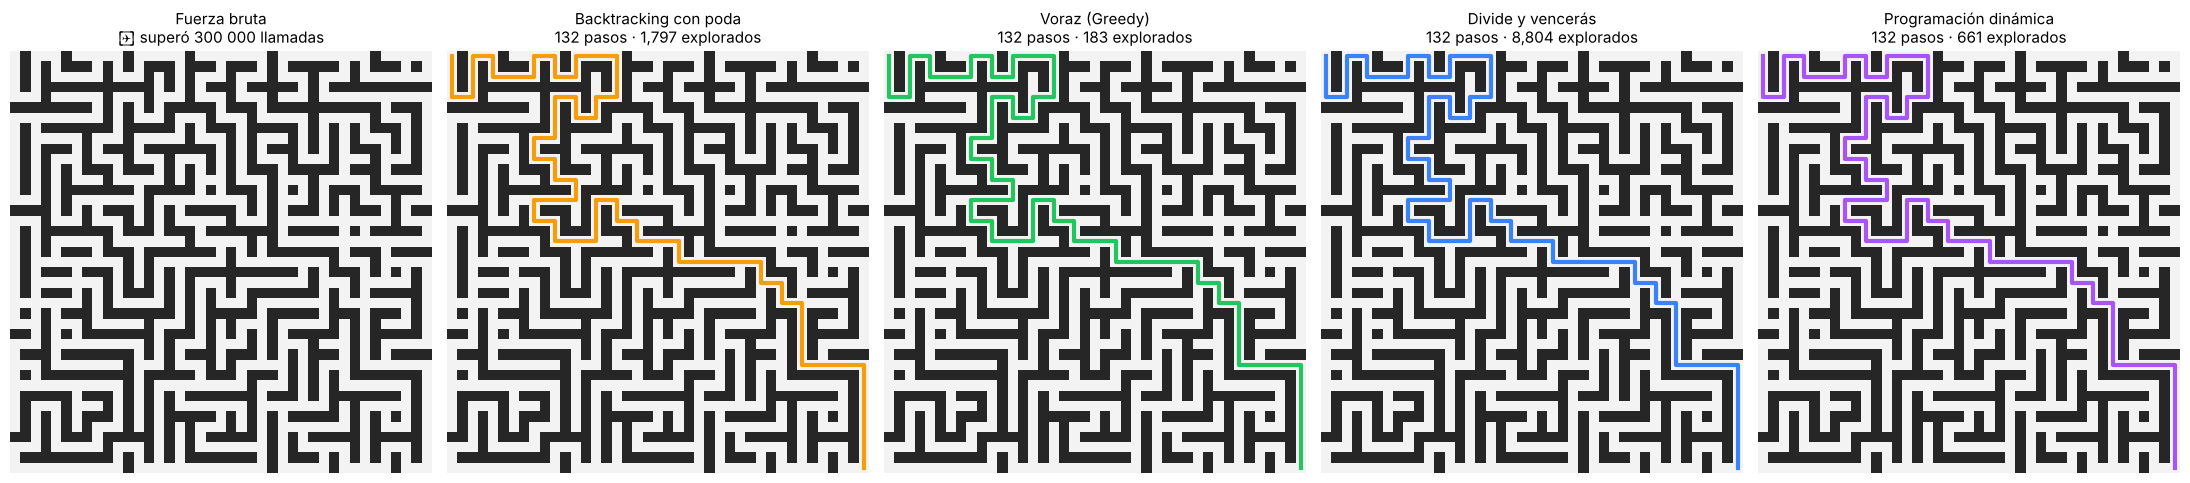

In [10]:
import matplotlib.pyplot as plt
import numpy as np

COLORES = {"Fuerza bruta": "#ef4444", "Backtracking con poda": "#f59e0b", "Voraz (Greedy)": "#22c55e",
           "Divide y vencerás": "#3b82f6", "Programación dinámica": "#a855f7"}

tablero = generar_laberinto(41, 41, ciclos=0.08, semilla=3)
fin = (40, 40)
fig, ejes = plt.subplots(1, 5, figsize=(22, 5))
for eje, (nombre, algoritmo) in zip(ejes, ALGORITMOS.items()):
    imagen = np.array([[0.15 if c == PARED else 0.95 for c in fila] for fila in tablero])
    eje.imshow(imagen, cmap="gray", vmin=0, vmax=1)
    try:
        camino, explorados = algoritmo(tablero, (0, 0), fin, limite=300_000) if nombre == "Fuerza bruta" \
            else algoritmo(tablero, (0, 0), fin)
        ys, xs = zip(*camino)
        eje.plot(xs, ys, color=COLORES[nombre], linewidth=3)
        eje.set_title(f"{nombre}\n{len(camino) - 1} pasos · {explorados:,} explorados", fontsize=11)
    except LimiteExcedido:
        eje.set_title(f"{nombre}\n❌ superó 300 000 llamadas", fontsize=11)
    eje.axis("off")
plt.tight_layout()
plt.show()

## 10. Experimento: laberintos gigantescos 🏔️

Medimos cada algoritmo en dos familias de laberintos de tamaño creciente (de 11×11 hasta **2001×2001**, unos 2 millones de casillas libres):

* **Perfectos** (un único camino) y
* **Con ciclos** (10 % de paredes extra derribadas → muchísimos caminos alternativos).

Para cada corrida registramos:
* ⏱️ **Tiempo** (`time.perf_counter`, mejor de 3 repeticiones en tamaños pequeños),
* 💾 **Memoria pico** (`tracemalloc`, en una corrida aparte para no contaminar el tiempo). En los algoritmos **recursivos** solo se mide hasta 81×81:
  `tracemalloc` recorre toda la pila de llamadas en cada asignación, así que con recursión profunda la medición tardaría minutos
  (y además no cuenta los marcos de la pila, por lo que su memoria real es *mayor* que la reportada),
* 🔎 **Casillas exploradas**,
* 📏 **Longitud del camino** y si es **óptimo**.

Reglas para que el experimento termine en un tiempo razonable:
* Si un algoritmo supera su presupuesto de operaciones o tarda más de **30 s** en un tamaño, ya no se prueba en los tamaños mayores
  (y en esa corrida no se mide la memoria, porque con `tracemalloc` tardaría varias veces más).
* Los algoritmos **recursivos** (fuerza bruta y backtracking) se prueban hasta 1001×1001: por encima, la pila de llamadas
  superaría el millón de niveles.

In [11]:
TAMANOS = [11, 21, 41, 81, 161, 321, 641, 1001, 1501, 2001]
FAMILIAS = {"perfecto": 0.0, "ciclos": 0.10}
LIMITE_SEGUNDOS = 30
RECURSIVOS = {"Fuerza bruta", "Backtracking con poda"}
MAX_RECURSIVO = 1001  # por encima, la pila de llamadas superaría el millón de niveles


def medir(algoritmo, tablero, inicio, fin, con_memoria=True):
    """Devuelve (camino, explorados, segundos, memoria_pico_kb o None)."""
    repeticiones = 3 if len(tablero) <= 81 else 1
    segundos = float("inf")
    for _ in range(repeticiones):
        t0 = time.perf_counter()
        camino, explorados = algoritmo(tablero, inicio, fin)
        segundos = min(segundos, time.perf_counter() - t0)
    if not con_memoria or segundos > LIMITE_SEGUNDOS:  # con tracemalloc tardaría varias veces más
        return camino, explorados, segundos, None
    tracemalloc.start()
    algoritmo(tablero, inicio, fin)
    _, pico = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return camino, explorados, segundos, pico / 1024


resultados = {"tamanos": TAMANOS, "familias": {}}
for familia, ciclos in FAMILIAS.items():
    print(f"\n════════ Laberintos {familia.upper()} ════════")
    filas = {nombre: [] for nombre in ALGORITMOS}
    descartados = set()
    for n in TAMANOS:
        tablero = generar_laberinto(n, n, ciclos=ciclos, semilla=n)
        inicio, fin = (0, 0), (n - 1, n - 1)
        libres = sum(fila.count(LIBRE) for fila in tablero)
        optimo = None
        print(f"\n{n}×{n}  ({libres:,} casillas libres)")
        for nombre in reversed(list(ALGORITMOS)):  # la PD va primero: da la longitud óptima de referencia
            fila = {"n": n, "libres": libres}
            if nombre in descartados or (nombre in RECURSIVOS and n > MAX_RECURSIVO):
                fila["estado"] = "omitido"
            else:
                try:
                    camino, explorados, seg, kb = medir(ALGORITMOS[nombre], tablero, inicio, fin,
                                                         con_memoria=nombre not in RECURSIVOS or n <= 81)
                    if optimo is None:
                        optimo = len(camino) - 1
                    fila.update(estado="ok", ms=seg * 1000, kb=kb, explorados=explorados,
                                pasos=len(camino) - 1, optimo=len(camino) - 1 == optimo)
                    if seg > LIMITE_SEGUNDOS:
                        descartados.add(nombre)
                except LimiteExcedido:
                    fila["estado"] = "limite"
                    descartados.add(nombre)
            filas[nombre].append(fila)
            if fila["estado"] == "ok":
                marca = "✓ óptimo" if fila["optimo"] else f"✗ (+{fila['pasos'] - optimo} pasos)"
                memoria = "—" if fila["kb"] is None else f"{fila['kb']:.1f}"
                print(f"  {nombre:<22} {fila['ms']:>11.2f} ms {memoria:>11} KB "
                      f"{fila['explorados']:>12,} explorados  {fila['pasos']:>6} pasos {marca}")
            else:
                print(f"  {nombre:<22} {'❌ superó el límite' if fila['estado'] == 'limite' else '— omitido'}")
    resultados["familias"][familia] = filas


════════ Laberintos PERFECTO ════════

11×11  (71 casillas libres)
  Programación dinámica         0.13 ms         1.6 KB           50 explorados      44 pasos ✓ óptimo
  Divide y vencerás             2.34 ms         6.1 KB        1,064 explorados      44 pasos ✓ óptimo
  Voraz (Greedy)                0.12 ms         3.3 KB           45 explorados      44 pasos ✓ óptimo
  Backtracking con poda         0.19 ms         5.3 KB           47 explorados      44 pasos ✓ óptimo
  Fuerza bruta                  0.11 ms         5.3 KB           51 explorados      44 pasos ✓ óptimo

21×21  (241 casillas libres)
  Programación dinámica         0.36 ms         4.5 KB          105 explorados      84 pasos ✓ óptimo
  Divide y vencerás             3.01 ms        24.0 KB        2,596 explorados      84 pasos ✓ óptimo
  Voraz (Greedy)                0.12 ms         6.8 KB           85 explorados      84 pasos ✓ óptimo
  Backtracking con poda         0.19 ms        13.2 KB           92 explorados      84

  Divide y vencerás            27.34 ms       119.0 KB       22,231 explorados     500 pasos ✓ óptimo
  Voraz (Greedy)                1.13 ms        27.2 KB          667 explorados     500 pasos ✓ óptimo
  Backtracking con poda         2.23 ms        95.0 KB          848 explorados     500 pasos ✓ óptimo
  Fuerza bruta                  1.24 ms        87.5 KB          877 explorados     500 pasos ✓ óptimo

81×81  (3,361 casillas libres)
  Programación dinámica         4.20 ms       123.1 KB        2,257 explorados    1312 pasos ✓ óptimo


  Divide y vencerás            97.59 ms       754.1 KB       74,326 explorados    1312 pasos ✓ óptimo
  Voraz (Greedy)                3.48 ms       108.3 KB        1,663 explorados    1312 pasos ✓ óptimo


  Backtracking con poda         6.96 ms       316.4 KB        2,226 explorados    1312 pasos ✓ óptimo


  Fuerza bruta                  6.49 ms       371.3 KB        3,317 explorados    1312 pasos ✓ óptimo

161×161  (13,121 casillas libres)
  Programación dinámica        33.50 ms       763.1 KB        9,443 explorados    4268 pasos ✓ óptimo


...

  Divide y vencerás         33346.30 ms           — KB   11,077,883 explorados    3880 pasos ✓ óptimo


  Voraz (Greedy)               25.75 ms      1293.3 KB        8,139 explorados    5704 pasos ✗ (+1824 pasos)
  Backtracking con poda  — omitido
  Fuerza bruta           — omitido



2001×2001  (2,104,438 casillas libres)


  Programación dinámica      5391.14 ms     97500.7 KB    2,104,278 explorados    5092 pasos ✓ óptimo
  Divide y vencerás      — omitido


  Voraz (Greedy)               35.52 ms      2062.9 KB       10,926 explorados    7436 pasos ✗ (+2344 pasos)
  Backtracking con poda  — omitido
  Fuerza bruta           — omitido


## 11. Gráficas comparativas

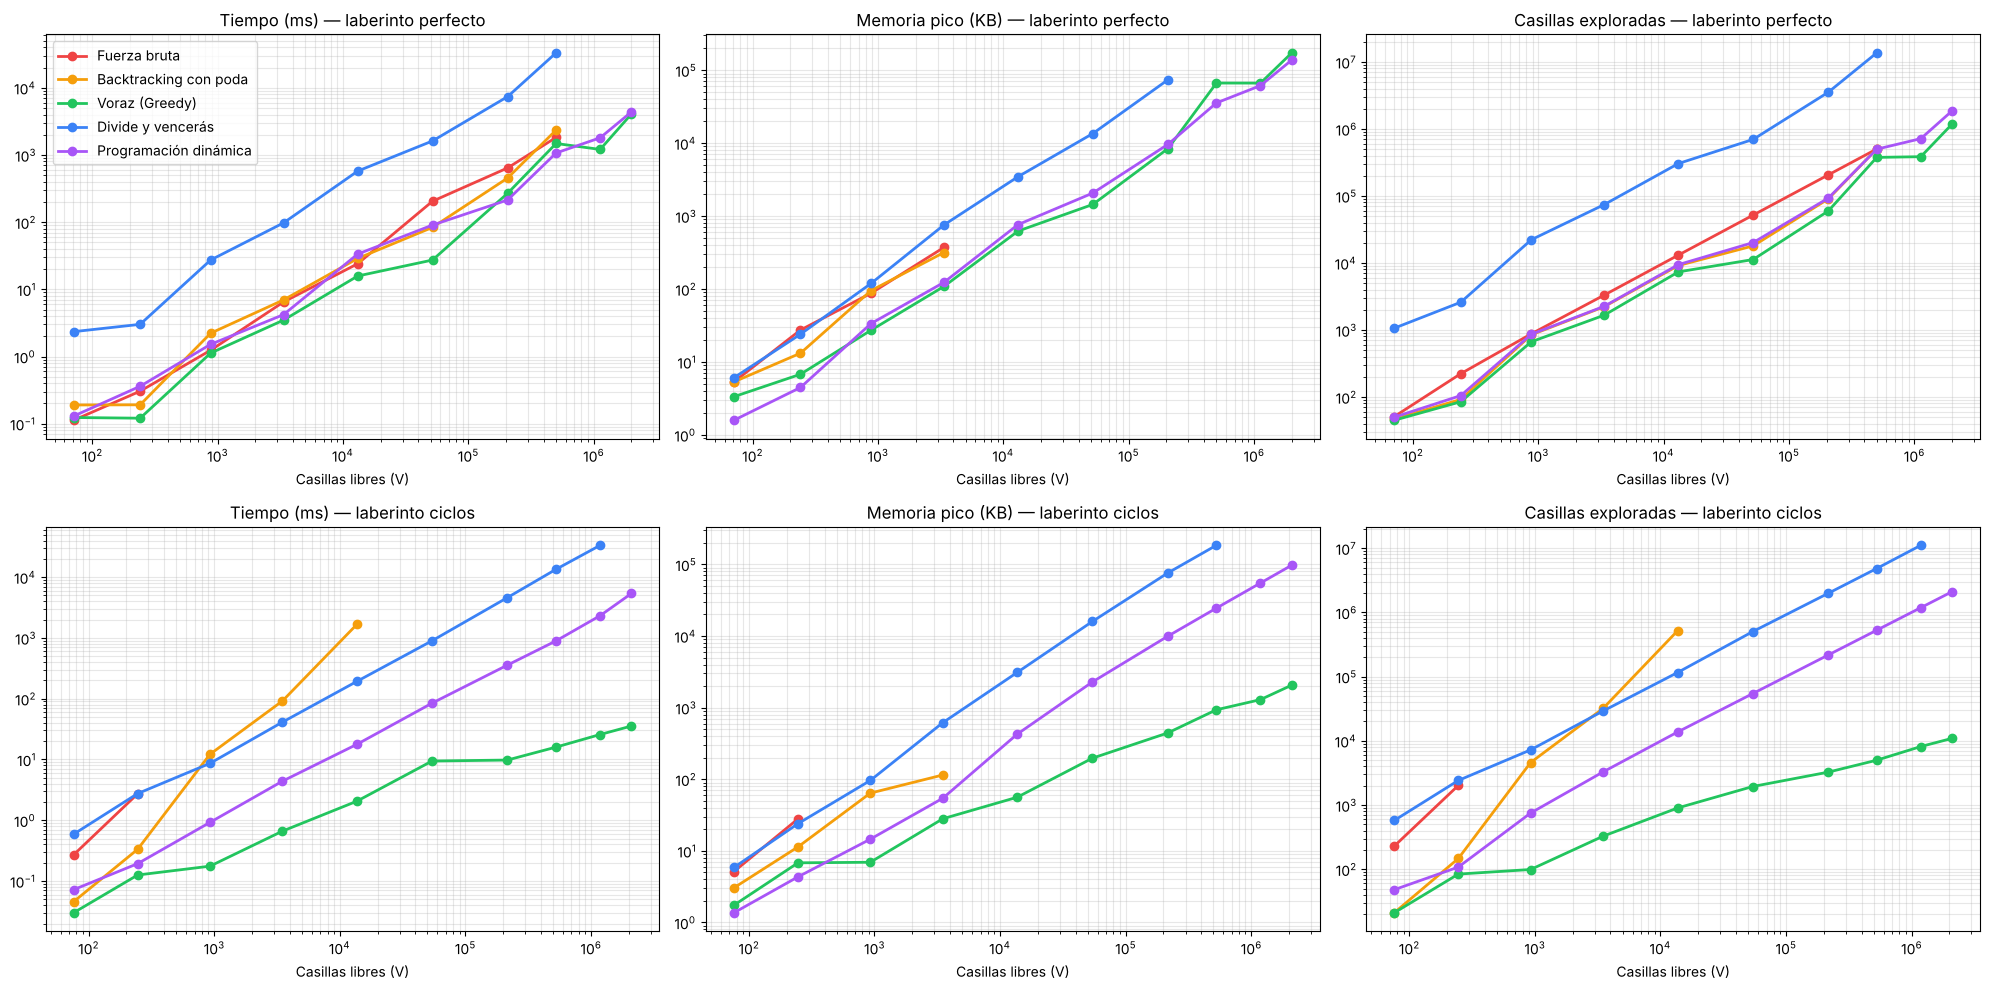

In [12]:
fig, ejes = plt.subplots(2, 3, figsize=(20, 10))
metricas = [("ms", "Tiempo (ms)"), ("kb", "Memoria pico (KB)"), ("explorados", "Casillas exploradas")]
for fila_ejes, (familia, filas) in zip(ejes, resultados["familias"].items()):
    for eje, (clave, titulo) in zip(fila_ejes, metricas):
        for nombre, datos in filas.items():
            puntos = [(d["libres"], d[clave]) for d in datos if d["estado"] == "ok" and d[clave] is not None]
            if puntos:
                eje.plot(*zip(*puntos), "o-", color=COLORES[nombre], label=nombre, linewidth=2)
        eje.set_xscale("log"); eje.set_yscale("log")
        eje.set_xlabel("Casillas libres (V)"); eje.set_title(f"{titulo} — laberinto {familia}")
        eje.grid(True, which="both", alpha=0.3)
ejes[0][0].legend()
plt.tight_layout()
plt.show()

### ¿Cuántas veces más lento que la programación dinámica?

En escala logarítmica las diferencias se ven pequeñas: una línea apenas "por encima" de otra puede ser 20 veces más lenta.
Aquí dividimos el tiempo de cada algoritmo entre el de la PD en el laberinto de **1001 × 1001**, el más grande donde corrieron los cinco.

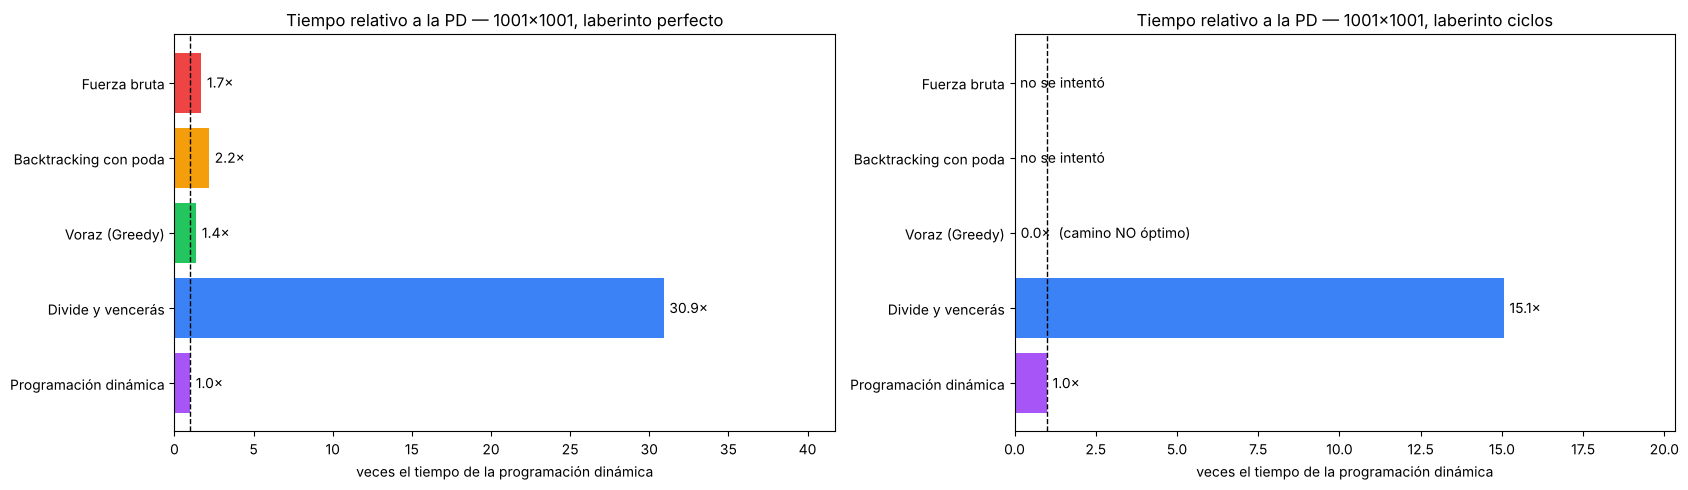

In [13]:
fig, ejes = plt.subplots(1, 2, figsize=(17, 5))
n = 1001
i = TAMANOS.index(n)
for eje, (familia, filas) in zip(ejes, resultados["familias"].items()):
    base = filas["Programación dinámica"][i]["ms"]
    nombres, valores, etiquetas = [], [], []
    for nombre, datos in filas.items():
        d = datos[i]
        nombres.append(nombre)
        if d["estado"] == "ok":
            valores.append(d["ms"] / base)
            etiquetas.append(f"{d['ms'] / base:.1f}×" + ("" if d["optimo"] else "  (camino NO óptimo)"))
        else:
            valores.append(0)
            etiquetas.append("no terminó" if d["estado"] == "limite" else "no se intentó")
    barras = eje.barh(nombres, valores, color=[COLORES[x] for x in nombres])
    eje.bar_label(barras, etiquetas, padding=4)
    eje.axvline(1, color="black", linewidth=1, linestyle="--")
    eje.set_title(f"Tiempo relativo a la PD — {n}×{n}, laberinto {familia}")
    eje.set_xlabel("veces el tiempo de la programación dinámica")
    eje.set_xlim(0, max(valores) * 1.35)
    eje.invert_yaxis()
plt.tight_layout()
plt.show()

## 12. Exportar resultados para la presentación web

Guardamos las mediciones en `resultados.js`; [`index.html`](index.html) lo carga automáticamente para dibujar sus gráficas.

In [14]:
with open("resultados.js", "w", encoding="utf-8") as archivo:
    archivo.write("// Generado por laberintos.ipynb — no editar a mano\n")
    archivo.write("window.RESULTADOS = " + json.dumps(resultados, ensure_ascii=False) + ";\n")
print("resultados.js actualizado ✔")

resultados.js actualizado ✔


## 13. Conclusiones 🏆

| Estrategia | Tiempo | Espacio | ¿Óptimo? | Laberinto más grande resuelto |
|---|---|---|---|---|
| Fuerza bruta | $O(4^{N \cdot M})$ | $O(N \cdot M)$ | ✅ | 21×21 con ciclos (1001×1001 solo si es perfecto) |
| Backtracking con poda | $O((N \cdot M)^2)$ peor caso | $O(N \cdot M)$ | ✅ | 161×161 con ciclos |
| Voraz (Greedy) | $O(N \cdot M \log(N \cdot M))$ | $O(N \cdot M)$ | ❌ | 2001×2001, con caminos más largos que el óptimo |
| Divide y vencerás | $O(d \log d)$ … $O(N \cdot M \cdot d)$ | $O(N \cdot M)$ | ✅ | 1001×1001 perfecto (≈ 33 s, unas 30 veces la PD) y 1501×1501 con ciclos |
| **Programación dinámica** | $\mathbf{O(N \cdot M)}$ | $\mathbf{O(N \cdot M)}$ | ✅ | **2001×2001 en ≈ 4,4 s** |

**🏆 Ganador: Programación dinámica (tabulación).** Es la única estrategia que a la vez:

1. garantiza el **camino más corto**,
2. tiene complejidad temporal **lineal** en el número de casillas — cada subproblema `dist[x][y]` se resuelve **una sola vez**,
3. usa memoria **lineal**, igual que las demás.

**Lecciones:**
* La **fuerza bruta** es correcta pero inutilizable en general: con ciclos el número de caminos crece exponencialmente y no termina ni en 41×41.
  En un laberinto *perfecto* parece rápida solo porque existe **un único** camino (el árbol de búsqueda no se ramifica): es su mejor caso, no su caso típico.
* La **poda** convierte lo exponencial en polinomial, pero sigue siendo cuadrática en el peor caso y recursiva (pila profunda).
* El **voraz** es veloz y explora pocas casillas, pero **no es confiable**: entrega caminos más largos que el óptimo.
* **Divide y vencerás** es elegante y óptimo, pero sus subproblemas **se solapan**: recorre las mismas zonas una y otra vez.
  Eso es exactamente lo que la **programación dinámica** elimina guardando cada resultado en una tabla.

### En cualquier caso: programación dinámica

Si se exige el **camino más corto**, la programación dinámica es el algoritmo más óptimo en todos los laberintos que probamos:
siempre es exacta, tiene tiempo y memoria $O(N \cdot M)$, rinde igual con y sin ciclos (2001×2001 en ≈ 4,4 s perfecto y ≈ 5,4 s con ciclos),
es la exacta más rápida en los laberintos grandes y, al ser iterativa, no tiene límite de recursión.

### ¿Qué algoritmo conviene según el caso favorable?

| Algoritmo | Caso favorable | Por qué funciona ahí | Evidencia medida | Cuándo evitarlo |
|---|---|---|---|---|
| **Programación dinámica** | Cualquier laberinto, sobre todo si se exige el camino más corto o es grande | Llena `dist` una sola vez por capas; no depende de cuántos caminos haya | 2001×2001: ≈ 4,4 s (perfecto) y ≈ 5,4 s (con ciclos), siempre óptimo | Prácticamente nunca (solo usa memoria para la tabla) |
| **Voraz** | Basta con *un* camino rápido, o el laberinto es perfecto (un único camino) | Va directo a la meta y explora muy pocas casillas; en un laberinto perfecto el único camino es el más corto | Con ciclos en 2001×2001: más de 100× más rápido que la PD, pero 2 344 pasos de más | Si el camino debe ser el más corto |
| **Backtracking con poda** | Laberintos pequeños o con pocos ciclos; problemas con restricciones extra que se puedan podar | Las podas descartan ramas enteras si encuentra pronto una buena solución | Perfecto 1001×1001: ≈ 2,2× la PD; con ciclos llegó a 161×161 y superó el límite en 321×321 | Laberintos grandes con ciclos |
| **Divide y vencerás** | Pasillos estrechos, o trabajo que se quiera repartir en paralelo (A→M y M→B son independientes) | Con pasillos estrechos el costo queda en $\Theta(d \log d)$ con solo $\log d$ niveles de recursión | Siempre óptimo, pero ≈ 31× la PD en 1001×1001 (perfecto) y ≈ 14× en 1501×1501 (con ciclos) | Laberintos grandes o abiertos (subproblemas solapados) |
| **Fuerza bruta** | Laberintos diminutos o perfectos; como referencia para verificar a los demás | Con un solo camino no hay ramas que probar | Perfecto 1001×1001: ≈ 1,7× la PD; con ciclos solo terminó hasta 21×21 | Cualquier laberinto mediano con ciclos |
